# Primeira rede neural com Keras

Do perceptron isolado até um modelo compilado e pronto para treinar,
passando pelas duas APIs de construção do Keras: **Sequential** e **Funcional**.

## [1] Importação de bibliotecas

In [1]:
"""
Define uma seed global para garantir reprodutibilidade máxima
no treinamento com TensorFlow/Keras.

NOTE 1: Para aulas, deixo essa parte comentada para demonstrar o
        comportamento estocástico das práticas com DL.
NOTE 2: Na prática diária com DL, determinamos as SEEDs somente no
        split dos dados, pois operações em GPU sofrem perda de
        performance quando forçadas ao determinismo.
NOTE 3: Em alguns casos de treinamento avançado com DL, não é
        possível estabelecer 100% de determinismo devido à alta
        dependência de operações paralelizadas.
"""
# 1. Variáveis de ambiente (precisam ser definidas ANTES de importar TF!
import os
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'      # força kernels determinísticos
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'    # determinismo em GPU (cuDNN)


import tensorflow as tf
import keras
import numpy as np
from absl import logging

# seeds determinadas após importação dos módulos
keras.utils.set_random_seed(SEED)
# 3. Habilita operações determinísticas no TF (TF >= 2.8)
# NOTE: Haverá perda de performance
# NOTE: Em alguns casos, ainda não será 100% determinístico (paralelismo!)
tf.config.experimental.enable_op_determinism()

# silenciar alguns avisos do tf que não serão relevantes
tf.get_logger().setLevel('ERROR')
logging.set_verbosity(logging.ERROR)

## [2] Função utilitária de visualização

Sempre que criamos um modelo, queremos ver seu resumo (camadas, formatos
e número de parâmetros) e seu diagrama. Uma função evita repetir as
mesmas duas linhas para cada modelo construído neste notebook.

In [18]:
def describe_model(model, expand_nested=False):
    model.summary()
    return keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, expand_nested=expand_nested)

## [3] Uma camada isolada (perceptrons)

Uma camada `Dense` com N unidades representa N perceptrons em paralelo,
cada um recebendo as mesmas entradas (features).

In [3]:
FEATURES = 2  # quantidade de entradas (x1, x2)
UNITS = 4     # quantidade de perceptrons na camada

layer = keras.layers.Dense(UNITS, activation='relu', name='layer1')

# a camada só é inicializada quando conhece o formato da entrada
# ("declaração preguiçosa"). Aqui forçamos essa inicialização manualmente.
# None representa o eixo de batch (explicado nas próximas aulas!).
layer.build((None, FEATURES))

print("\n ================ \n")
print('pesos das entradas (X):')
print(layer.weights[0].numpy())  # índice 0 = pesos das entradas (Kernel)
print("\n ================ \n")
print('pesos dos vieses (bias):')
print(layer.weights[1].numpy())  # índice 1 = pesos dos vieses



pesos das entradas (X):
[[ 0.7163782   0.32525706 -0.28257847  0.8999791 ]
 [-0.8438778   0.3046646   0.94099975 -0.66417575]]


pesos dos vieses (bias):
[0. 0. 0. 0.]


In [4]:
layer.weights

[<Variable path=layer1/kernel, shape=(2, 4), dtype=float32, value=[[ 0.7163782   0.32525706 -0.28257847  0.8999791 ]
  [-0.8438778   0.3046646   0.94099975 -0.66417575]]>,
 <Variable path=layer1/bias, shape=(4,), dtype=float32, value=[0. 0. 0. 0.]>]

## [4] Testando a camada com uma entrada

In [11]:
inputs = np.random.random((32, FEATURES))
print("INPUTS:", inputs)

print("OUTPUTS:", layer(inputs))

INPUTS: [[0.83244264 0.21233911]
 [0.18182497 0.18340451]
 [0.30424224 0.52475643]
 [0.43194502 0.29122914]
 [0.61185289 0.13949386]
 [0.29214465 0.36636184]
 [0.45606998 0.78517596]
 [0.19967378 0.51423444]
 [0.59241457 0.04645041]
 [0.60754485 0.17052412]
 [0.06505159 0.94888554]
 [0.96563203 0.80839735]
 [0.30461377 0.09767211]
 [0.68423303 0.44015249]
 [0.12203823 0.49517691]
 [0.03438852 0.9093204 ]
 [0.25877998 0.66252228]
 [0.31171108 0.52006802]
 [0.54671028 0.18485446]
 [0.96958463 0.77513282]
 [0.93949894 0.89482735]
 [0.59789998 0.92187424]
 [0.0884925  0.19598286]
 [0.04522729 0.32533033]
 [0.38867729 0.27134903]
 [0.82873751 0.35675333]
 [0.28093451 0.54269608]
 [0.14092422 0.80219698]
 [0.07455064 0.98688694]
 [0.77224477 0.19871568]
 [0.00552212 0.81546143]
 [0.70685734 0.72900717]]
OUTPUTS: tf.Tensor(
[[0.4171555  0.33545008 0.         0.6081505 ]
 [0.         0.11501672 0.12120377 0.04182584]
 [0.         0.25883165 0.40782335 0.        ]
 [0.0636742  0.22922038 0.1519

## [5] Modelo sequencial (API Sequential)

Duas formas equivalentes de empilhar camadas: adicionando uma a uma com
`.add()`, ou passando uma lista de camadas diretamente ao `Sequential`.

In [12]:
model = keras.Sequential()
model.add(keras.layers.Input(shape=(2,), name='inputs'))
model.add(keras.layers.Dense(4, activation='relu', name='hidden1'))
model.add(keras.layers.Dense(4, activation='relu', name='hidden2'))
model.add(keras.layers.Dense(4, activation='relu', name='hidden3'))
model.add(keras.layers.Dense(1, activation='sigmoid', name='output'))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden1 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden2 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden3 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57 (228.00 B)

 Trainable params: 57 (228.00 B)

 Non-trainable params: 0 (0.00 B)

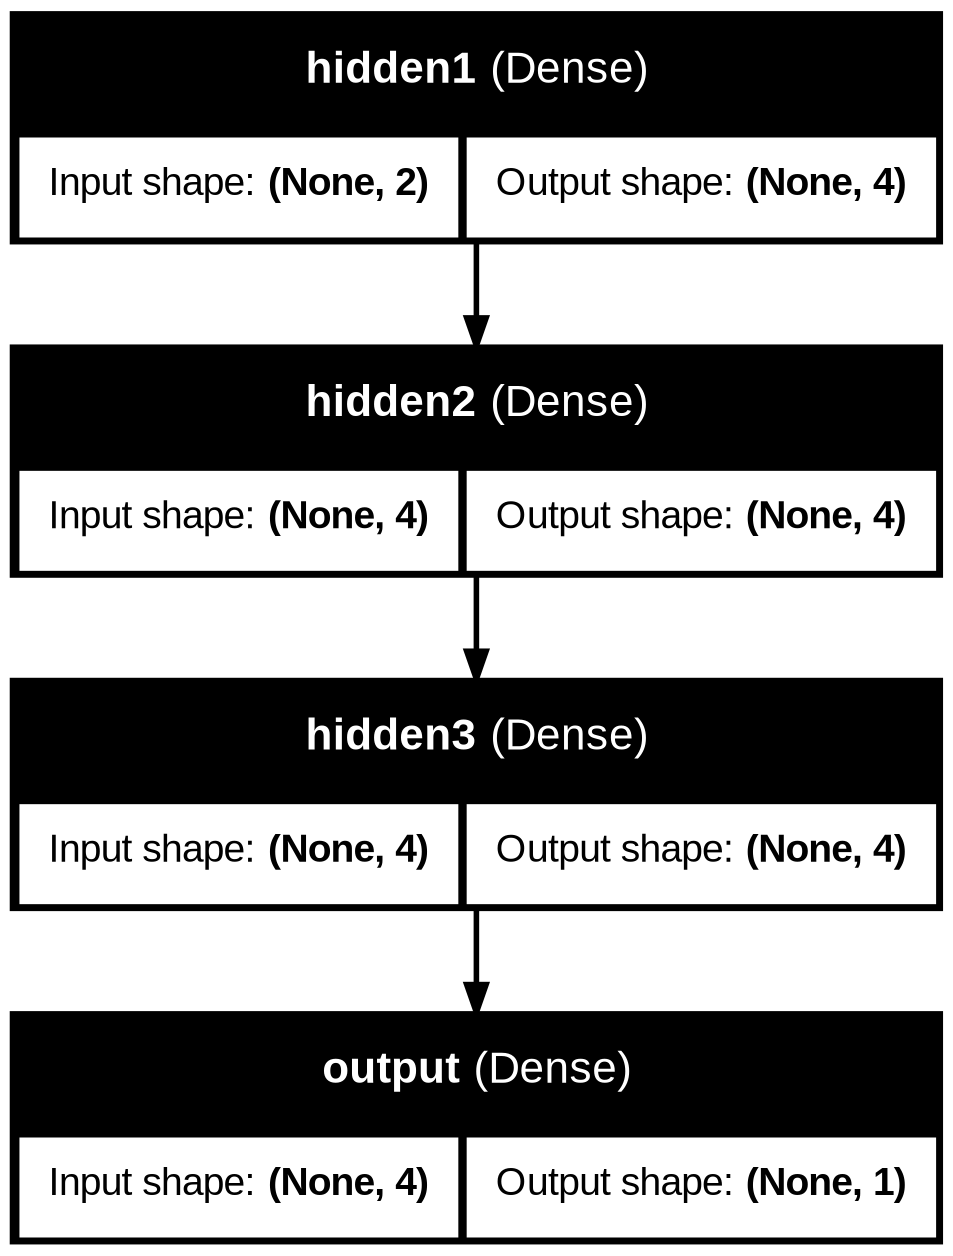

In [14]:
describe_model(model)

In [ ]:
# forma equivalente (mesmo resultado, sintaxe mais compacta)
model = keras.Sequential([
    keras.layers.Input(shape=(2,), name='inputs'),
    keras.layers.Dense(4, activation='relu', name='hidden1'),
    keras.layers.Dense(4, activation='relu', name='hidden2'),
    keras.layers.Dense(4, activation='relu', name='hidden3'),
    keras.layers.Dense(1, activation='sigmoid', name='output')
])

describe_model(model)

In [15]:
model.weights

[<Variable path=sequential/hidden1/kernel, shape=(2, 4), dtype=float32, value=[[ 0.9583118  -0.03596425  0.5321958   0.48574543]
  [ 0.63199854 -0.7626424   0.406291    0.0587976 ]]>,
 <Variable path=sequential/hidden1/bias, shape=(4,), dtype=float32, value=[0. 0. 0. 0.]>,
 <Variable path=sequential/hidden2/kernel, shape=(4, 4), dtype=float32, value=[[ 0.5938315  -0.0399968  -0.20391107 -0.5433048 ]
  [-0.182931    0.62269896 -0.69929993 -0.10784209]
  [-0.7450089  -0.6730807  -0.2794662   0.2429387 ]
  [-0.29028332  0.8529317   0.13200623 -0.35877943]]>,
 <Variable path=sequential/hidden2/bias, shape=(4,), dtype=float32, value=[0. 0. 0. 0.]>,
 <Variable path=sequential/hidden3/kernel, shape=(4, 4), dtype=float32, value=[[ 0.54723734  0.23631757  0.00202179  0.31737489]
  [ 0.6226055   0.32912284  0.63731736  0.6830861 ]
  [-0.5318656   0.3110705  -0.45218942  0.41363877]
  [-0.19109923 -0.24630153 -0.03996706 -0.7157982 ]]>,
 <Variable path=sequential/hidden3/bias, shape=(4,), dtype=f

## [6] Modelo com a API Funcional (Functional API)

A API Funcional trata cada camada como uma função aplicada sobre a
camada anterior, permitindo topologias mais flexíveis que o Sequential.

In [ ]:
inputs = keras.layers.Input(shape=(3,), name='inputs')
x = keras.layers.Dense(4, activation='relu', name='hidden1')(inputs)
x = keras.layers.Dense(4, activation='relu', name='hidden2')(x)
x = keras.layers.Dense(4, activation='relu', name='hidden3')(x)
x = keras.layers.Dense(4, activation='relu', name='hidden4')(x)
outputs = keras.layers.Dense(1, activation='sigmoid', name='output')(x)

model = keras.Model(inputs, outputs)

describe_model(model)

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inputs (InputLayer)             │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 4)              │           316 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

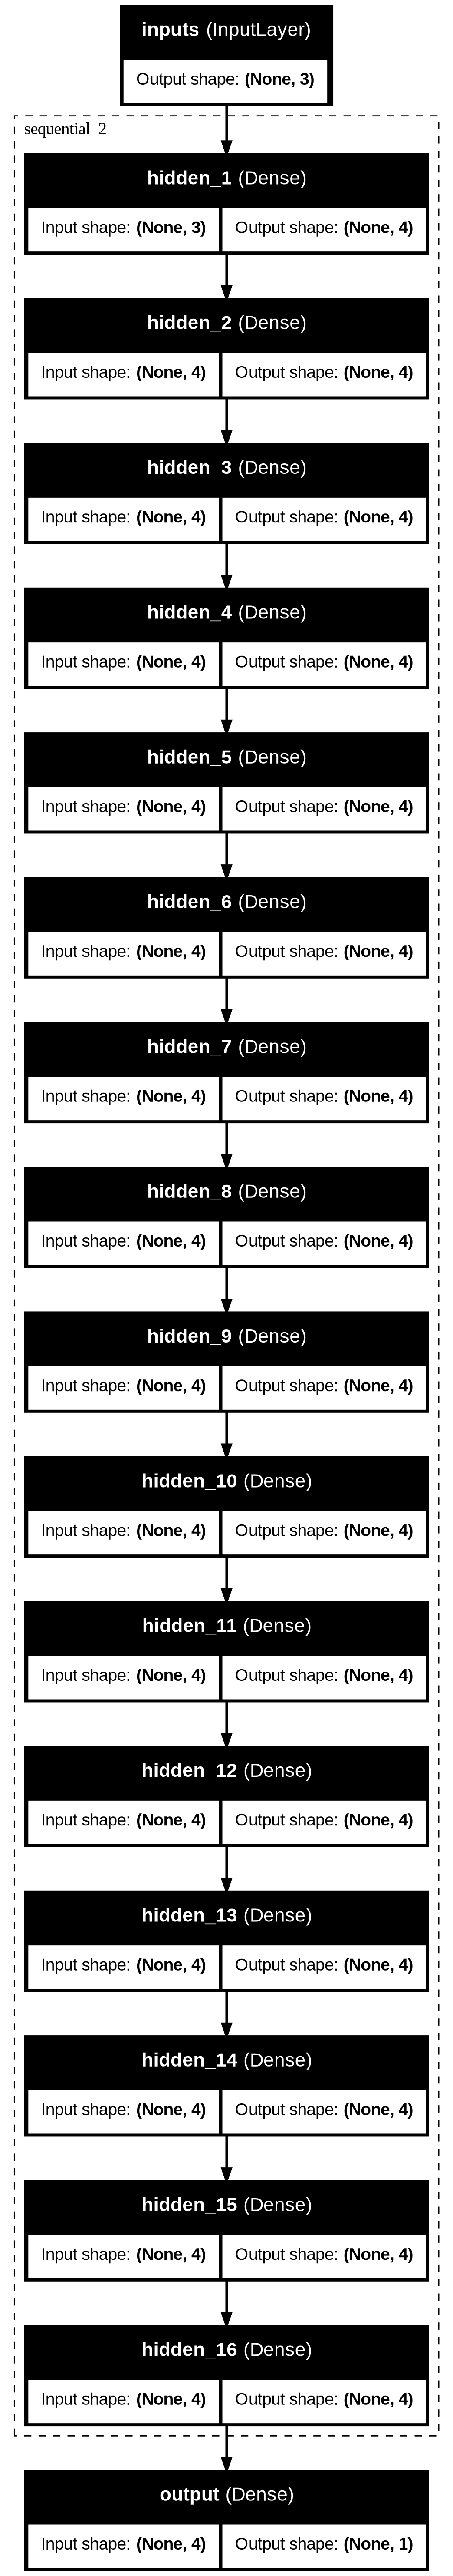

In [19]:
inputs = keras.layers.Input(shape=(3,), name='inputs')

x = keras.Sequential([keras.layers.Dense(4, activation='relu', name=f'hidden_{i}') for i in range(1, 16+1)])(inputs)

outputs = keras.layers.Dense(1, activation='sigmoid', name='output')(x)

model = keras.Model(inputs, outputs)

describe_model(model, expand_nested=True)

In [16]:
[keras.layers.Dense(4, activation='relu', name=f'hidden_{i}') for i in range(1, 16+1)]

[<Dense name=hidden_1, built=False>,
 <Dense name=hidden_2, built=False>,
 <Dense name=hidden_3, built=False>,
 <Dense name=hidden_4, built=False>,
 <Dense name=hidden_5, built=False>,
 <Dense name=hidden_6, built=False>,
 <Dense name=hidden_7, built=False>,
 <Dense name=hidden_8, built=False>,
 <Dense name=hidden_9, built=False>,
 <Dense name=hidden_10, built=False>,
 <Dense name=hidden_11, built=False>,
 <Dense name=hidden_12, built=False>,
 <Dense name=hidden_13, built=False>,
 <Dense name=hidden_14, built=False>,
 <Dense name=hidden_15, built=False>,
 <Dense name=hidden_16, built=False>]

## [7] Predição com pesos aleatórios (sem treino)

Como o modelo ainda não foi treinado, a predição reflete apenas os
pesos aleatórios inicializados — ainda não aprendeu nada.

In [25]:
inputs = np.random.random((1, 3)).astype('float32')
y_pred = model.predict(inputs)

print("INPUTS:", inputs)
print("OUTPUTS: ", y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
INPUTS: [[0.7132448  0.76078504 0.5612772 ]]
OUTPUTS:  [[0.5]]


## [8] Compilando o modelo para treino

A compilação define o otimizador, a função de perda e as métricas
usadas durante o treinamento.

In [ ]:
model.compile(
    optimizer='SGD',
    loss='binary_crossentropy',
    metrics=['accuracy']
)